Original Dataset Shape: (178, 14)
   alcohol  malic_acid   ash  alcalinity_of_ash  magnesium  total_phenols  \
0    14.23        1.71  2.43               15.6      127.0           2.80   
1    13.20        1.78  2.14               11.2      100.0           2.65   
2    13.16        2.36  2.67               18.6      101.0           2.80   
3    14.37        1.95  2.50               16.8      113.0           3.85   
4    13.24        2.59  2.87               21.0      118.0           2.80   

   flavanoids  nonflavanoid_phenols  proanthocyanins  color_intensity   hue  \
0        3.06                  0.28             2.29             5.64  1.04   
1        2.76                  0.26             1.28             4.38  1.05   
2        3.24                  0.30             2.81             5.68  1.03   
3        3.49                  0.24             2.18             7.80  0.86   
4        2.69                  0.39             1.82             4.32  1.04   

   od280/od315_of_diluted_wi

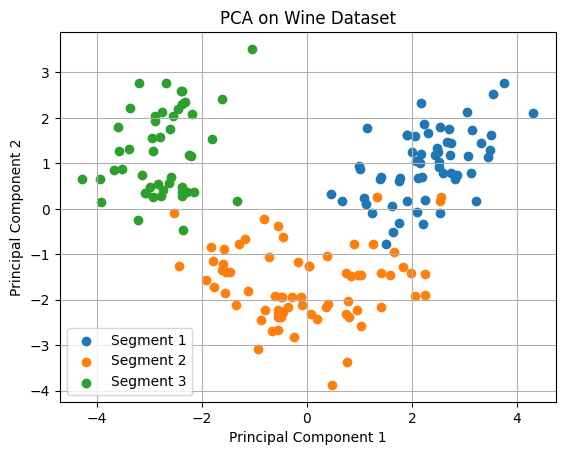

In [2]:
# Import required libraries
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

# Load dataset
df = pd.read_csv("Wine.csv")

print("Original Dataset Shape:", df.shape)
print(df.head())

# Separate features and target
X = df.drop("Customer_Segment", axis=1)
y = df["Customer_Segment"]

# Standardize the features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Apply PCA to reduce 13 features to 2 components
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

# Create a DataFrame of principal components
pca_df = pd.DataFrame(
    X_pca,
    columns=["Principal Component 1", "Principal Component 2"]
)

pca_df["Customer_Segment"] = y.values

print("\nTransformed Dataset:")
print(pca_df.head())

# Display explained variance ratio
print("\nExplained Variance Ratio:")
print(pca.explained_variance_ratio_)

# Display total variance captured
total_variance = sum(pca.explained_variance_ratio_) * 100

print("Total Variance Captured:", round(total_variance, 2), "%")

# Visualize the principal components
for segment in sorted(y.unique()):
    subset = pca_df[pca_df["Customer_Segment"] == segment]

    plt.scatter(
        subset["Principal Component 1"],
        subset["Principal Component 2"],
        label=f"Segment {segment}"
    )

# Add graph labels and title
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("PCA on Wine Dataset")
plt.legend()
plt.grid(True)
plt.show()